In [27]:
import numpy as np
import pandas as pd
import os
from urllib.parse import unquote
import random
from time import sleep
import pickle
import json
import copy
import re
import regex
import matplotlib.pyplot as plt
from utils import effective_path
import ast
import parse

import sys
sys.path.append('../')


%load_ext autoreload
%autoreload 2

random.seed(42)
#pd.set_option('display.max_colwidth', None)

PATH_IN = '../../data/wikispeedia/wikispeedia_paths-and-graph/'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Analyse agent run data

In [79]:
PATH_RUNS = "../../logs/inference/multiruns/multiturn_demo_comparison/2023-10-11_17-46-25"

system_demo_df = pd.read_csv(os.path.join(PATH_RUNS, "0/agent_runs.tsv"), sep="\t")
multiturn_demo_df = pd.read_csv(os.path.join(PATH_RUNS, "1/agent_runs.tsv"), sep="\t")

# get the llama2 tokenizer
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-chat-hf")

# unite these two dfs, and add a column to indicate which system it is
system_demo_df['fewshot_mode'] = 'system_prompt'
multiturn_demo_df['fewshot_mode'] = 'multiturn'
runs_df = pd.concat([system_demo_df, multiturn_demo_df], ignore_index=True)

runs_df['end_page'] = runs_df.apply(lambda x: x['path'].split(";")[-1], axis=1)
# response history is a string of the form ['response1', 'response2', ...], we have to use parse
runs_df['end_response'] = runs_df.apply(lambda x: ast.literal_eval(x['response_history'])[-1], axis=1)
runs_df["end_user_prompt"]=runs_df.apply(lambda x: ast.literal_eval(x['user_prompt_history'])[-1], axis=1)
runs_df["end_user_prompt_num_tokens"]=runs_df.apply(lambda x: len(tokenizer.tokenize(x['end_user_prompt'])), axis=1)
runs_df['end_next_page'] = runs_df.apply(lambda x: parse.search("\"next_page\": \"{}\"", x['end_response'])[0], axis=1)
runs_df['reached_goal'] = runs_df.apply(lambda x: x['end_page'] == x['tgt'], axis=1)
runs_df['path_length'] = runs_df.apply(lambda x: len(x['path'].split(";")) - 1, axis=1)


In [80]:
runs_df.head()


,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,fewshot_mode,end_page,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length
0,0,LinkClickAgent,Albinism,Tungsten,Albinism;Niger;United_States;Vietnam;Cambodia;...,3,8,2,"[""User: I'm currently on the page Albinism and...","['Assistant:\n{\n ""next_page"": ""Niger""\n}', '...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Tungsten""\n}",User: I'm currently on the page United_States ...,1869,Tungsten,False,8
1,1,LinkClickAgent,Heraclius,Gender,Heraclius;Muhammad;Islam;Sultan;Egypt;Sudan,3,5,2,"[""User: I'm currently on the page Heraclius an...","['Assistant:\n{\n ""next_page"": ""Muhammad""\n}'...",system_prompt,Sudan,"Assistant:\n{\n ""next_page"": ""Gender""\n}",User: I'm currently on the page Sudan and the ...,747,Gender,False,5
2,2,LinkClickAgent,"Salt_Lake_City,_Utah",Drum_and_bass,"Salt_Lake_City,_Utah;Jazz;Miles_Davis;Jazz;Mil...",3,7,2,"[""User: I'm currently on the page Salt_Lake_Ci...","['Assistant:\n{\n ""next_page"": ""Jazz""\n}', 'A...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Drum_and_bass""\n}",User: I'm currently on the page United_States ...,1873,Drum_and_bass,False,7
3,3,LinkClickAgent,History_of_post-Soviet_Russia,Oviraptor,History_of_post-Soviet_Russia;Vladimir_Lenin;M...,3,4,2,"[""User: I'm currently on the page History_of_p...","['Assistant:\n{\n ""next_page"": ""Vladimir_Leni...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Oviraptor""\n}",User: I'm currently on the page United_States ...,1871,Oviraptor,False,4
4,4,LinkClickAgent,Archbishop_of_Canterbury,Dead_Sea,Archbishop_of_Canterbury;Thomas_Cranmer;Willia...,3,5,2,"[""User: I'm currently on the page Archbishop_o...","['Assistant:\n{\n ""next_page"": ""Thomas_Cranme...",system_prompt,London,"Assistant:\n{\n ""next_page"": ""Dead_Sea""\n}",User: I'm currently on the page London and the...,666,Dead_Sea,False,5


In [31]:
runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2 and end_page == 'United_States'")


,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,fewshot_mode,end_page,end_response,reached_goal,path_length
0,0,LinkClickAgent,Albinism,Tungsten,Albinism;Niger;United_States;Vietnam;Cambodia;...,3,8,2,"[""User: I'm currently on the page Albinism and...","['Assistant:\n{\n ""next_page"": ""Niger""\n}', '...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Tungsten""\n}",False,8
2,2,LinkClickAgent,"Salt_Lake_City,_Utah",Drum_and_bass,"Salt_Lake_City,_Utah;Jazz;Miles_Davis;Jazz;Mil...",3,7,2,"[""User: I'm currently on the page Salt_Lake_Ci...","['Assistant:\n{\n ""next_page"": ""Jazz""\n}', 'A...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Drum_and_bass""\n}",False,7
3,3,LinkClickAgent,History_of_post-Soviet_Russia,Oviraptor,History_of_post-Soviet_Russia;Vladimir_Lenin;M...,3,4,2,"[""User: I'm currently on the page History_of_p...","['Assistant:\n{\n ""next_page"": ""Vladimir_Leni...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Oviraptor""\n}",False,4
5,5,LinkClickAgent,Taoism,Franklin_D._Roosevelt,Taoism;Buddhism;India;United_States,3,3,2,"[""User: I'm currently on the page Taoism and t...","['Assistant:\n{\n ""next_page"": ""Buddhism""\n}'...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Franklin_D._Roo...",False,3
7,7,LinkClickAgent,Seawater,Tripoli,Seawater;Ocean;Northern_Mariana_Islands;United...,3,3,2,"[""User: I'm currently on the page Seawater and...","['Assistant:\n{\n ""next_page"": ""Ocean""ity\n}'...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Bahamas""\n}",False,3
10,10,LinkClickAgent,Romania,U2,Romania;Nadia_Comăneci;Pelé;David_Beckham;Mich...,3,5,2,"[""User: I'm currently on the page Romania and ...","['Assistant:\n{\n ""next_page"": ""Nadia_Comănec...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Uzbekistan""\n}",False,5
13,13,LinkClickAgent,Novel,Mark_Twain_House,Novel;James_Bond;United_States,3,2,2,"[""User: I'm currently on the page Novel and th...","['Assistant:\n{\n ""next_page"": ""James_Bond""\n...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Mark_Twain_Hous...",False,2
16,16,LinkClickAgent,Star_Trek__Deep_Space_Nine,Zinc,Star_Trek__Deep_Space_Nine;Soviet_Union;Moscow...,3,8,2,"[""User: I'm currently on the page Star_Trek__D...","['Assistant:\n{\n ""next_page"": ""Soviet_Union""...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Zinc""\n}",False,8
18,18,LinkClickAgent,Axe,Florida_East_Coast_Railway,Axe;France;United_States,3,2,2,"[""User: I'm currently on the page Axe and the ...","['Assistant:\n{\n ""next_page"": ""France""\n}', ...",system_prompt,United_States,"Assistant:\n{\n ""next_page"": ""Florida_East_Co...",False,2


In [51]:
runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2 and end_page == 'United_States'")[['src', 'tgt', 'path', 'num_errors', 'end_page', 'end_response', 'end_next_page']]


,src,tgt,path,num_errors,end_page,end_response,end_next_page
0,Albinism,Tungsten,Albinism;Niger;United_States;Vietnam;Cambodia;...,2,United_States,"Assistant:\n{\n ""next_page"": ""Tungsten""\n}",Tungsten
2,"Salt_Lake_City,_Utah",Drum_and_bass,"Salt_Lake_City,_Utah;Jazz;Miles_Davis;Jazz;Mil...",2,United_States,"Assistant:\n{\n ""next_page"": ""Drum_and_bass""\n}",Drum_and_bass
3,History_of_post-Soviet_Russia,Oviraptor,History_of_post-Soviet_Russia;Vladimir_Lenin;M...,2,United_States,"Assistant:\n{\n ""next_page"": ""Oviraptor""\n}",Oviraptor
5,Taoism,Franklin_D._Roosevelt,Taoism;Buddhism;India;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Franklin_D._Roo...",Franklin_D._Roosevelt
7,Seawater,Tripoli,Seawater;Ocean;Northern_Mariana_Islands;United...,2,United_States,"Assistant:\n{\n ""next_page"": ""Bahamas""\n}",Bahamas
10,Romania,U2,Romania;Nadia_Comăneci;Pelé;David_Beckham;Mich...,2,United_States,"Assistant:\n{\n ""next_page"": ""Uzbekistan""\n}",Uzbekistan
13,Novel,Mark_Twain_House,Novel;James_Bond;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Mark_Twain_Hous...",Mark_Twain_House
16,Star_Trek__Deep_Space_Nine,Zinc,Star_Trek__Deep_Space_Nine;Soviet_Union;Moscow...,2,United_States,"Assistant:\n{\n ""next_page"": ""Zinc""\n}",Zinc
18,Axe,Florida_East_Coast_Railway,Axe;France;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Florida_East_Co...",Florida_East_Coast_Railway


In [60]:
# how many paths include United_States
runs_df["includes_us"] = runs_df.apply(lambda x: 'United_States' in x['path'].split(";"), axis=1)
runs_df.query("fewshot_mode == 'system_prompt' and includes_us == True").count()

agent_id               11
agent_type             11
src                    11
tgt                    11
path                   11
fewshot                11
num_actions            11
num_errors             11
user_prompt_history    11
response_history       11
fewshot_mode           11
end_page               11
end_response           11
end_next_page          11
reached_goal           11
path_length            11
includes_us            11
dtype: int64

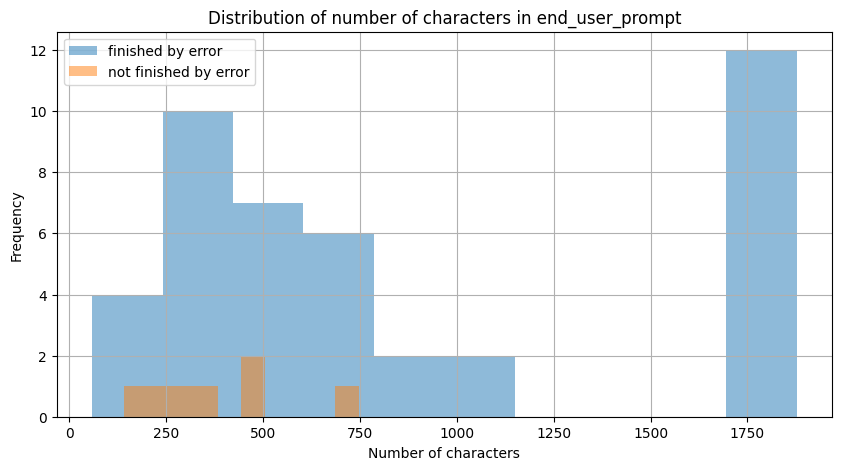

In [83]:
# runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2").end_user_prompt.tolist()
# runs_df.end_user_prompt.str.len().hist()
# plt.xlabel('Number of characters')
# plt.ylabel('Frequency')
# plt.title('Distribution of number of characters in end_user_prompt')

plt.figure(figsize=(10, 5))

runs_df[runs_df['num_errors'] == 2].end_user_prompt_num_tokens.hist(alpha=0.5, label='finished by error')
runs_df[runs_df['num_errors'] != 2].end_user_prompt_num_tokens.hist(alpha=0.5, label='not finished by error')

plt.xlabel('Number of characters')
plt.ylabel('Frequency')
plt.title('Distribution of number of characters in end_user_prompt')
plt.legend()

plt.show()


# Build paths_real_processed_df
`paths_real_df` (from Akhil) has the columns:
 - hashed_ip: user identifier
 - timestamp: time of the game
 - src, tgt: source and target pages
 - is_path_finished: whether the user reached the target page
 - failure_type: reason for failure (restart, timout, ...)
 - path: path taken (including backtracks)
 - hpl: Human Path Length (number of clicks by human, including backtracks)
 - spl: Shortest Path Length (shortest possible path length for that pair)
 - duration_in_sec: time taken by user
 - target_in_degree: number of incoming links to target page
 - user_path_rating: 1-5 rating of path difficulty by user

We're gonna add:
 - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
 - effective_path: path taken by user excluding backtracks
 - hepl: Human Effective Path Length (effective path length for that game instance)
 - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)

The final df is `paths_real_processed_df`

In [ ]:
# `paths_real_df` (from Akhil) has the columns:
#  - hashed_ip: user identifier
#  - timestamp: time of the game
#  - src, tgt: source and target pages
#  - is_path_finished: whether the user reached the target page
#  - failure_type: reason for failure (restart, timout, ...)
#  - path: path taken (including backtracks)
#  - hpl: Human Path Length (number of clicks by human, including backtracks)
#  - spl: Shortest Path Length (shortest possible path length for that pair)
#  - duration_in_sec: time taken by user
#  - target_in_degree: number of incoming links to target page
#  - user_path_rating: 1-5 rating of path difficulty by user

# We're gonna add:
#  - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
#  - effective_path: path taken by user excluding backtracks
#  - hepl: Human Effective Path Length (effective path length for that game instance)
#  - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)

# The final df is `paths_real_processed_df`

paths_real_processed_df = pd.read_csv(PATH_IN + 'paths_real_df.csv')

paths_real_processed_df["effective_path"] = paths_real_processed_df.apply(lambda row: effective_path(row["path"]), axis=1)
paths_real_processed_df["hepl"] = paths_real_processed_df.apply(lambda row: len(row["effective_path"].split(";"))-1, axis=1)

# add a column that is the shortest human path length for that pair, by choosing the minimum path_length for all games with that pair
shpl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hpl": "min"}).reset_index().rename(columns={"hpl": "shpl"})
shepl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hepl": "min"}).reset_index().rename(columns={"hepl": "shepl"})

paths_real_processed_df = pd.merge(paths_real_processed_df, shpl, on=['src', 'tgt'], how='left')
paths_real_processed_df = pd.merge(paths_real_processed_df, shepl, on=['src', 'tgt'], how='left')
paths_real_processed_df

,hashed_ip,timestamp,src,tgt,is_path_finished,failure_type,path,hpl,spl,duration_in_sec,target_in_degree,user_path_rating,effective_path,hepl,shpl,shepl
0,6a3701d319fc3754,1297740409,14th_century,African_slave_trade,1,NaN,14th_century;15th_century;16th_century;Pacific_Ocean;Atlantic_Ocean;Accra;Africa;Atlantic_slave_trade;African_slave_trade,8,3,166,7,NaN,14th_century;15th_century;16th_century;Pacific_Ocean;Atlantic_Ocean;Accra;Africa;Atlantic_slave_trade;African_slave_trade,8,4.0,4.0
1,3824310e536af032,1344753412,14th_century,African_slave_trade,1,NaN,14th_century;Europe;Africa;Atlantic_slave_trade;African_slave_trade,4,3,88,7,3.0,14th_century;Europe;Africa;Atlantic_slave_trade;African_slave_trade,4,4.0,4.0
2,415612e93584d30e,1349298640,14th_century,African_slave_trade,1,NaN,14th_century;Niger;Nigeria;British_Empire;Slavery;Africa;Atlantic_slave_trade;African_slave_trade,7,3,138,7,NaN,14th_century;Niger;Nigeria;British_Empire;Slavery;Africa;Atlantic_slave_trade;African_slave_trade,7,4.0,4.0
3,64dd5cd342e3780c,1265613925,14th_century,Greece,1,NaN,14th_century;Renaissance;Ancient_Greece;Greece,3,2,37,246,NaN,14th_century;Renaissance;Ancient_Greece;Greece,3,3.0,3.0
4,015245d773376aab,1366730828,14th_century,John_F._Kennedy,1,NaN,14th_century;Italy;Roman_Catholic_Church;HIV;Ronald_Reagan;President_of_the_United_States;John_F._Kennedy,6,3,175,60,3.0,14th_century;Italy;Roman_Catholic_Church;HIV;Ronald_Reagan;President_of_the_United_States;John_F._Kennedy,6,5.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76188,109ed71f571d86e9,1389787605,Franz_Kafka,Cholera,0,restart,Franz_Kafka;Tuberculosis;World_Health_Organization;Malaria;Philippines;<;Sub-Saharan_Africa;Ghana,7,3,180,38,NaN,Franz_Kafka;Tuberculosis;World_Health_Organization;Malaria;Sub-Saharan_Africa;Ghana,5,NaN,NaN
76189,232f992e57d43e8d,1389787697,Modern_history,Hollandic,0,restart,Modern_history,0,3,6,8,NaN,Modern_history,0,NaN,NaN
76190,2e09a7224600a7cd,1389798400,Computer_programming,The_Beatles,0,timeout,Computer_programming;Linguistics;Culture;Popular_culture;<,4,3,1900,61,NaN,Computer_programming;Linguistics;Culture,2,4.0,4.0
76191,60af9e2138051b96,1389799481,Jamaica,Alan_Turing,0,timeout,Jamaica;United_Kingdom;World_War_II;Battle_of_Midway,3,3,1903,11,NaN,Jamaica;United_Kingdom;World_War_II;Battle_of_Midway,3,NaN,NaN


In [ ]:
paths_real_processed_df.to_csv(PATH_IN + 'paths_real_processed.tsv', sep='\t', index=False)